# TP 17 — Classifieur d'images par rayon

Objectif : reconnaître le rayon d'un produit à partir de sa photo de face, pour la brique `src/classifieur_images.py` appelée par l'API du TP 23.

Données : photos du bucket public `openfoodfacts-images`, version 400 px. Licence CC BY-SA, **contributeurs Open Food Facts**.

Règles suivies dans ce notebook :
- uniquement des photos réelles ;
- découpage fait avant toute augmentation, augmentation appliquée au seul entraînement ;
- modèle et seuil choisis sur la validation, test ouvert une seule fois à la fin ;
- chaque score lu par rapport au plancher annoncé en 1.7.

## 0. Configuration

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # masque les messages techniques de TensorFlow

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

GRAINE = 42
keras.utils.set_random_seed(GRAINE)

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES = RACINE / "data" / "images"
MODELES = RACINE / "models"

print(sys.executable)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

/home/administrateur/venvs/nutriscope/bin/python
TensorFlow 2.20.0 | Keras 3.13.2
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Jeu de données

### 1.1 Rayons retenus et lien avec le périmètre

7 rayons sur les 15 du manifest, choisis pour coller aux 6 rayons de `docs/cadrage/perimetre.md` :

| Rayon téléchargé | Rayon du périmètre |
|---|---|
| `eaux`, `sodas` | Boissons |
| `yaourts`, `fromages` | Produits laitiers |
| `cereales` | Céréales et petit-déjeuner |
| `pates` | Plats préparés et conserves (approximation) |
| `sauces` | Sauces et condiments |

**Écarts.** « Biscuits et snacks » n'est pas couvert (`biscuits` et `chips` existent dans le manifest mais n'ont pas été retenus). « Plats préparés » n'est représenté qu'indirectement par `pates`, qui mélange pâtes sèches, pâtes fraîches et quelques plats cuisinés. Deux paires visuellement proches sont gardées volontairement (`eaux`/`sodas`, `yaourts`/`fromages`) : ce sont les confusions que l'application rencontrera.

### 1.2 Inventaire et effectifs

In [2]:
df = pd.DataFrame(
    [{"chemin": str(p), "rayon": p.parent.name, "code": p.stem} for p in sorted(IMAGES.glob("*/*.jpg"))]
)
RAYONS = sorted(df["rayon"].unique())
print(len(df), "photos,", len(RAYONS), "rayons")
df["rayon"].value_counts().sort_index()

3500 photos, 7 rayons


rayon
cereales    500
eaux        500
fromages    500
pates       500
sauces      500
sodas       500
yaourts     500
Name: count, dtype: int64

### 1.3 Fichiers illisibles et doublons

In [3]:
from PIL import Image

def est_lisible(chemin):
    """Renvoie True si PIL arrive à ouvrir l'image et à la décoder entièrement."""
    try:
        with Image.open(chemin) as img:
            img.load()          # décode tous les pixels (verify() ne lit que l'en-tête)
        return True
    except Exception:
        return False

df["lisible"] = df["chemin"].apply(est_lisible)    # applique la fonction à chaque ligne
print("Illisibles :", (~df["lisible"]).sum())       # ~ inverse True/False, sum compte les True
df[~df["lisible"]]
# - ouvrir chaque image avec PIL (Image.open(...).verify()) et compter celles qui échouent
# - vérifier qu'un même `code` n'apparaît pas dans deux rayons
# - décider quoi faire des cas trouvés, et le dire

Illisibles : 0


,chemin,rayon,code,lisible


In [4]:
# Un même code-barres présent plusieurs fois ?
doublons = df[df["code"].duplicated(keep=False)]    # keep=False : garde toutes les occurrences
print("Codes en double :", doublons["code"].nunique())
doublons.sort_values("code")

Codes en double : 0


,chemin,rayon,code,lisible


**Bilan.** Aucun fichier illisible et aucun code-barres en double : les 3 500 photos sont conservées.

### 1.4 Tailles et formats

In [5]:
def infos(chemin):
    with Image.open(chemin) as img:
        return img.width, img.height, img.mode     # mode : "RGB", "L" (gris), "RGBA" (transparence)...

df[["largeur", "hauteur", "mode"]] = df["chemin"].apply(lambda c: pd.Series(infos(c)))
df["ratio"] = df["largeur"] / df["hauteur"]        # >1 : image en largeur, <1 : en hauteur

print(df["mode"].value_counts())
df[["largeur", "hauteur", "ratio"]].describe()

mode
RGB    3500
Name: count, dtype: int64


,largeur,hauteur,ratio
count,3500.000000,3500.000000,3500.000000
mean,315.542571,380.312286,0.865531
std,77.673161,48.924126,0.336866
min,150.000000,150.000000,0.375000
25%,263.000000,400.000000,0.665000
50%,300.000000,400.000000,0.750000
75%,400.000000,400.000000,1.000000
max,400.000000,400.000000,2.666667


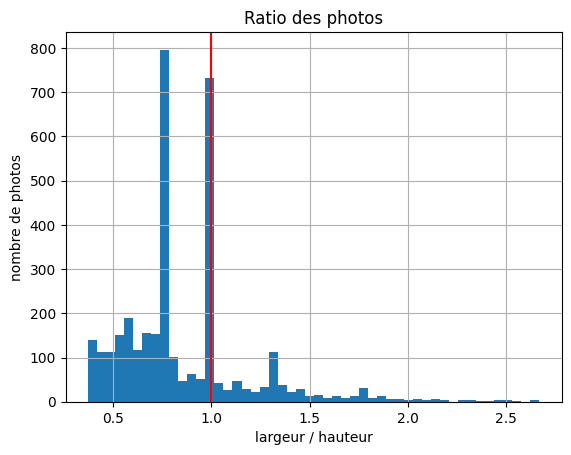

In [6]:
df["ratio"].hist(bins=50)
plt.axvline(1, color="red")         # ligne rouge = image carrée
plt.xlabel("largeur / hauteur"); plt.ylabel("nombre de photos")
plt.title("Ratio des photos")
plt.show()

**Constats.**
- Les 3 500 photos sont en RGB : aucune conversion n'est nécessaire.
- 3 449 photos font 400 px sur leur grand côté. Les 18 plus petites (200 à 300 px) seront agrandies, sans conséquence notable vu leur nombre.
- Les photos ne sont pas carrées : le ratio largeur/hauteur médian est de 0,75, et 62 % des photos sont plus hautes que larges (bouteilles, paquets). Les valeurs vont de 0,38 à 2,67.
- Le ratio dépend du rayon : il vaut 0,75 pour la plupart des rayons, mais 1,0 pour `fromages` et `yaourts`, dont les emballages sont plus ronds ou carrés.

**Décision.** Nous ramenons les images à un carré **sans les déformer**, en complétant avec des bandes (`tf.image.resize_with_pad`). Écrasée en carré, une bouteille perd sa silhouette, et c'est justement ce qui distingue `eaux` et `sodas` de `yaourts`. Le texte des étiquettes resterait lui aussi déformé.

**À surveiller.** La forme de l'image (et donc la largeur des bandes) est un indice sur le rayon. Si le modèle confond des rayons aux emballages de même forme, ou s'appuie trop sur la forme plutôt que sur le contenu, cela se verra dans la planche des erreurs (partie 5).

### 1.5 Planches par rayon

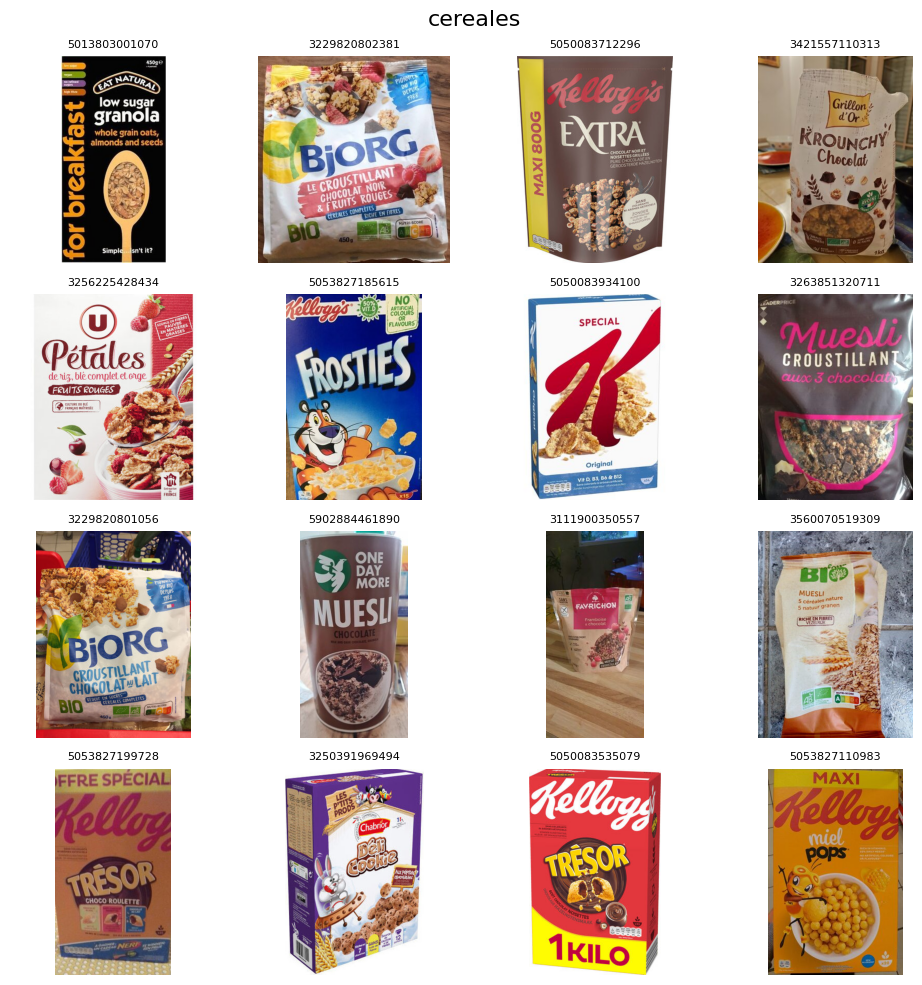

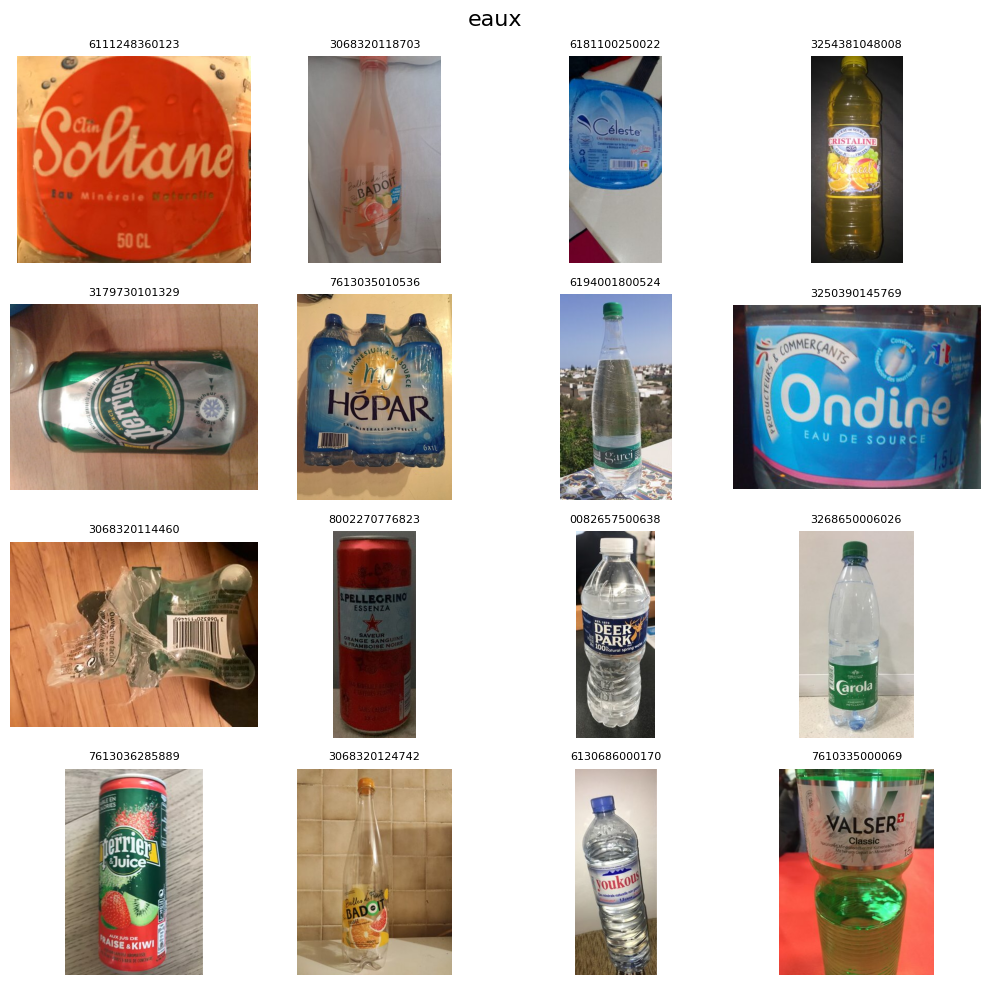

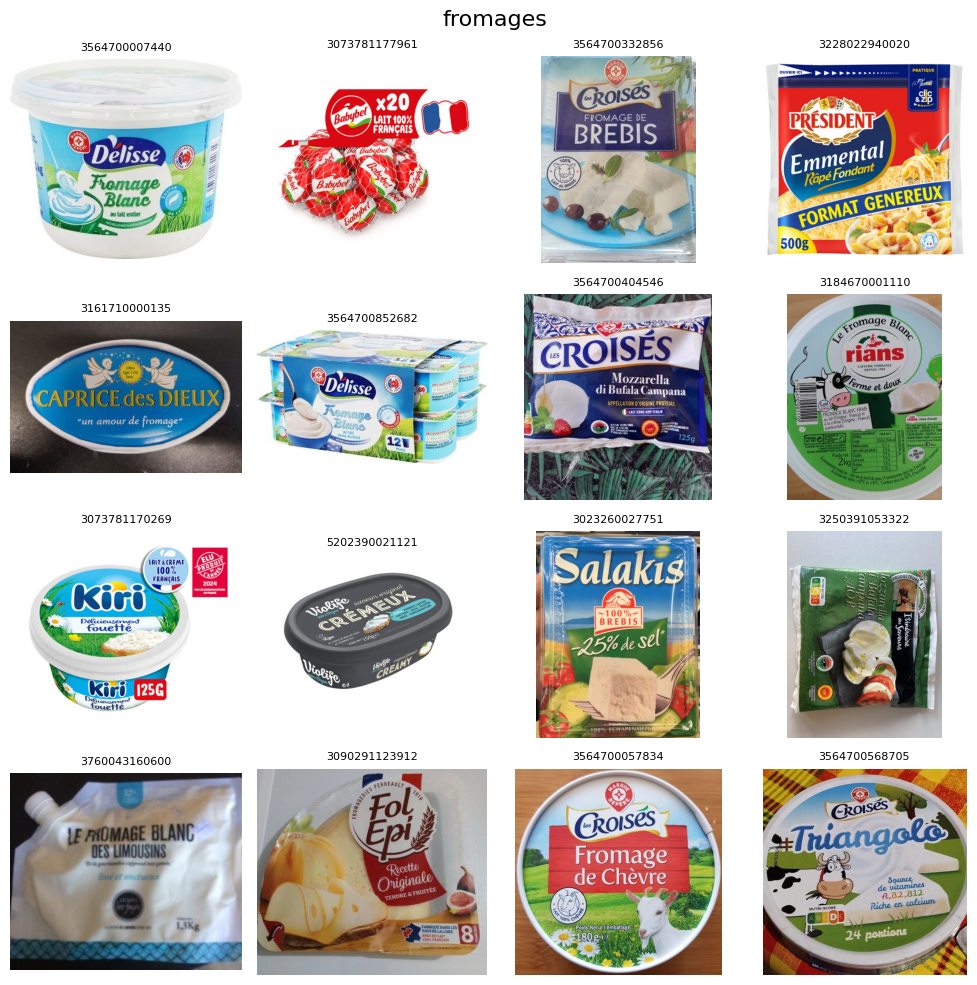

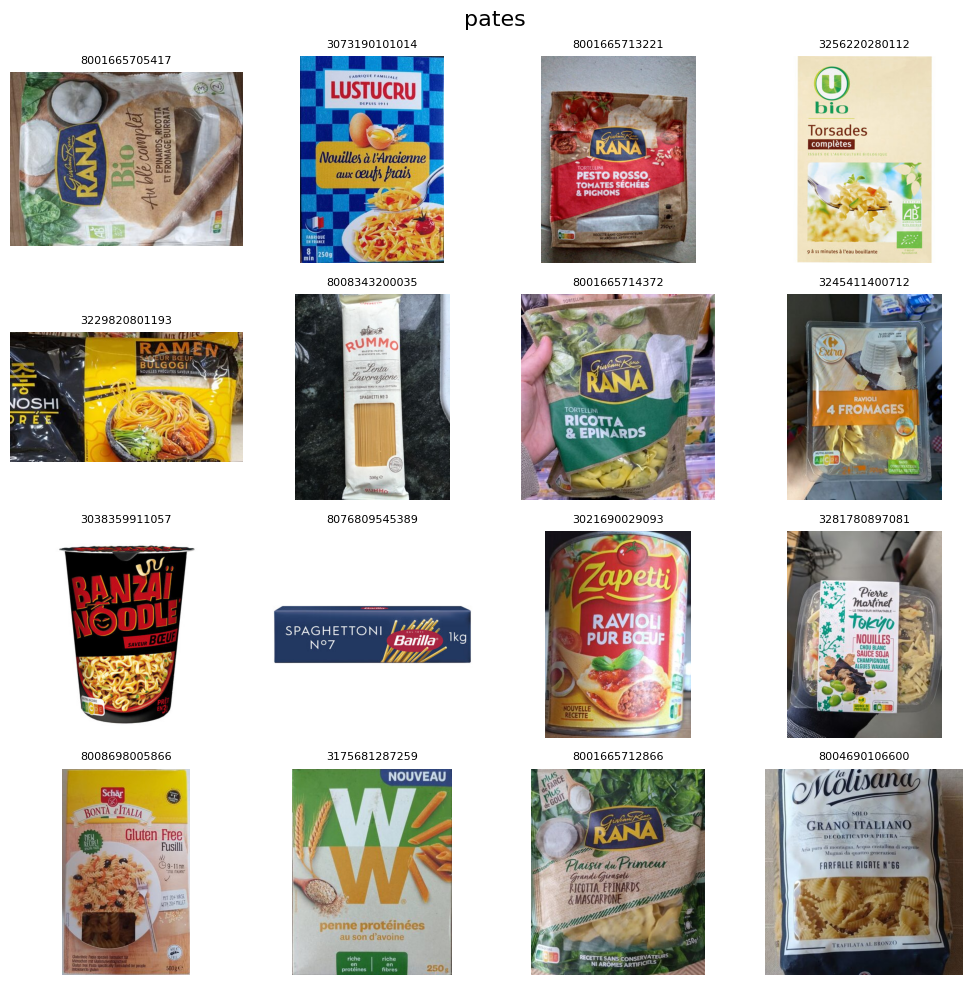

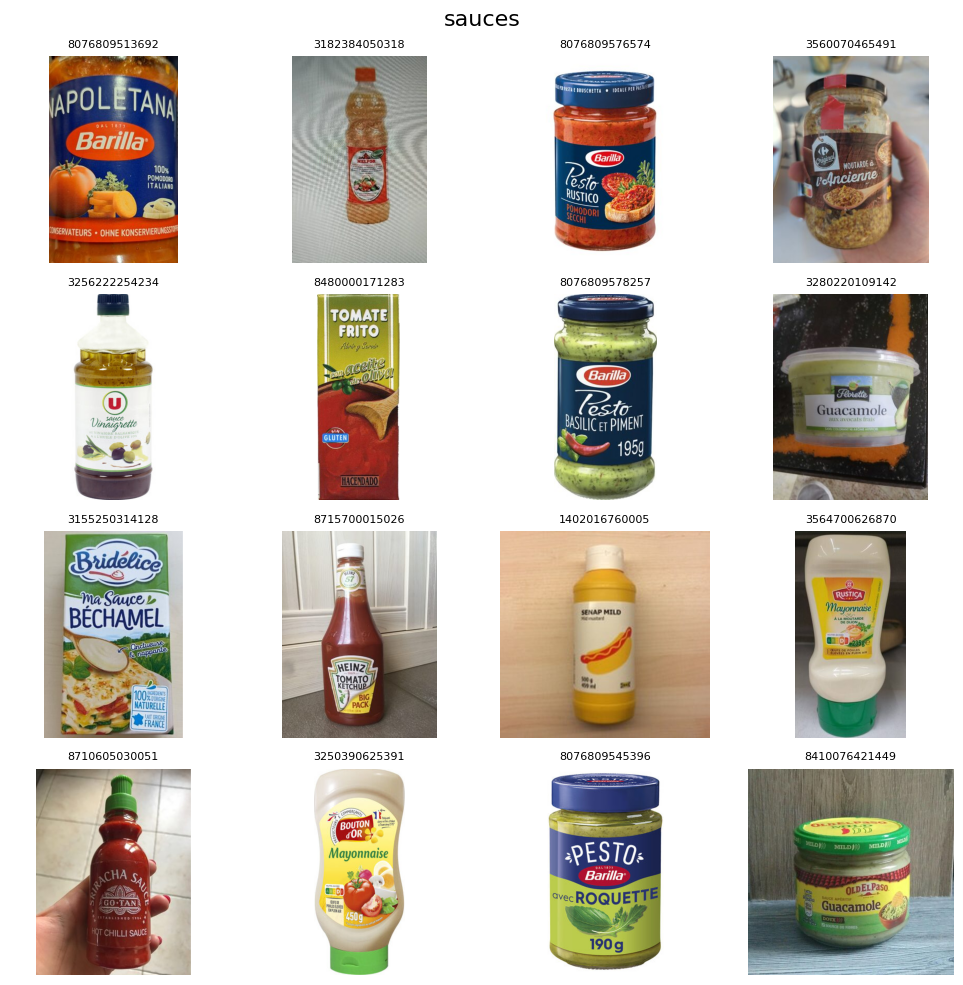

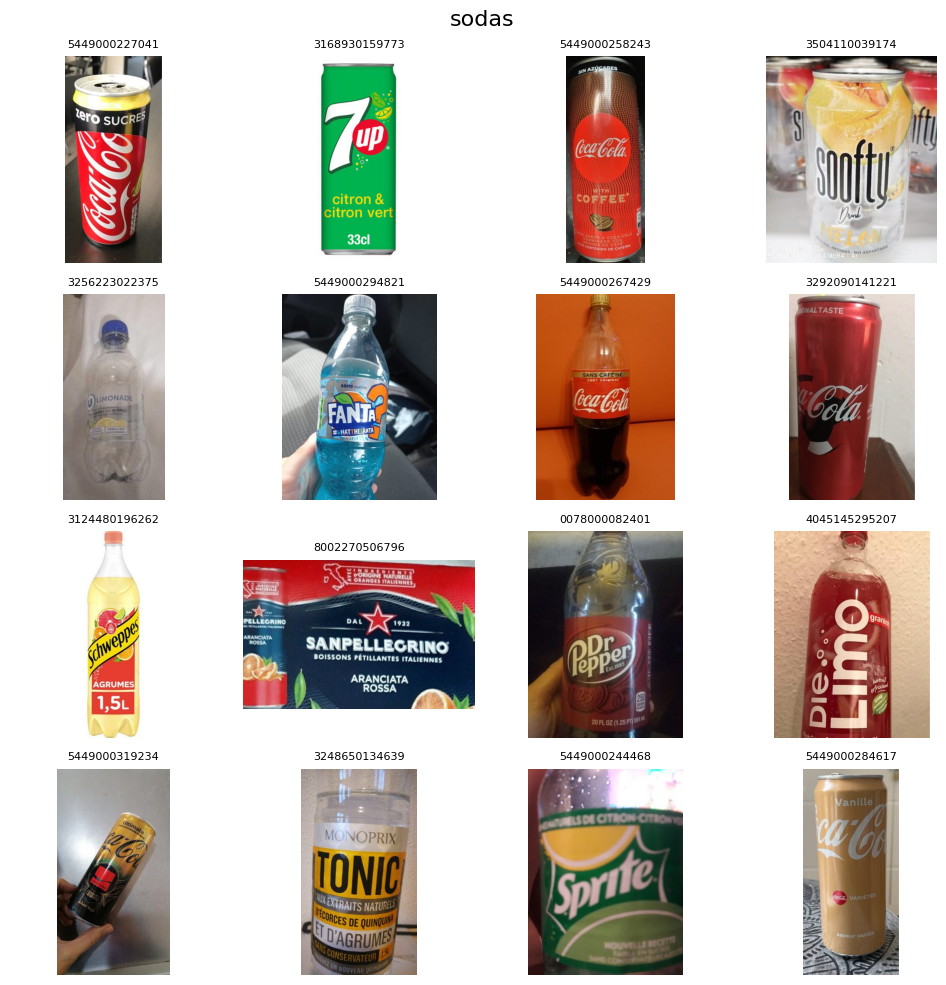

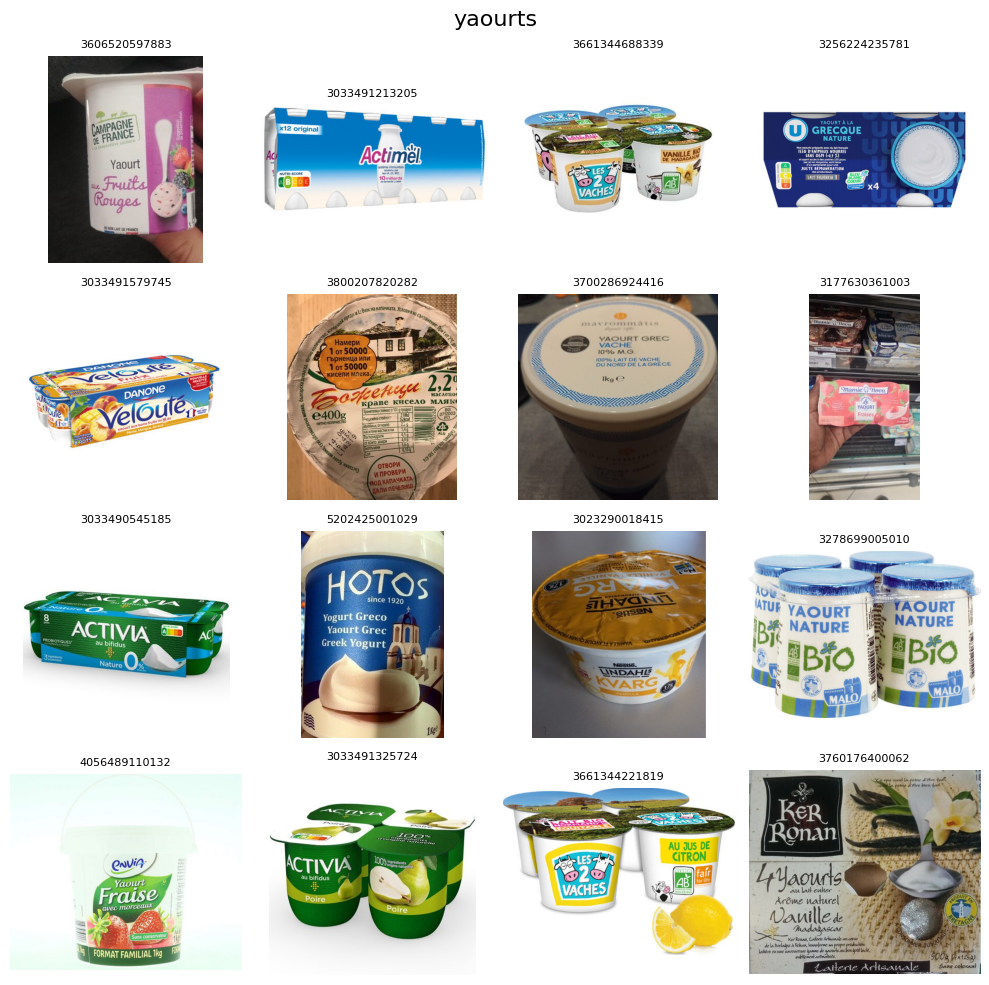

In [7]:
def afficher_planche(rayon, n=16):
    """Affiche n photos d'un rayon, tirées au hasard (toujours les mêmes grâce à la graine)."""
    photos = df[df["rayon"] == rayon].sample(n, random_state=GRAINE)   # n lignes au hasard du rayon

    fig, axes = plt.subplots(4, 4, figsize=(10, 10))                   # une grille de 4 x 4 cases
    for case, (_, ligne) in zip(axes.flat, photos.iterrows()):         # une photo par case
        case.imshow(Image.open(ligne["chemin"]))
        case.set_title(ligne["code"], fontsize=8)                      # le code-barres sous chaque photo
        case.axis("off")                                               # pas de graduations
    fig.suptitle(rayon, fontsize=16)
    plt.tight_layout()
    plt.show()

for rayon in RAYONS:
    afficher_planche(rayon)

**Observations.** Les images sont plutôt de bonne qualité dans l'ensemble, mais très hétérogènes. Deux types de photos se mélangent : des photos de studio sur fond blanc (fréquentes en `cereales` et `yaourts`) et des photos prises au smartphone, avec mains, fonds de cuisine, reflets et perspective (fréquentes en `eaux` et `sodas`).

L'échelle varie beaucoup : certains produits sont pris de très près (on ne voit que l'étiquette : Soltane, Ondine, Sprite), d'autres d'assez loin. Quelques produits sont de côté ou à l'horizontale, mais la plupart sont à la verticale.

| Rayon | Remarques |
|---|---|
| `cereales` | Le plus homogène : boîtes et sachets, souvent sur fond blanc. |
| `eaux` | Bouteilles, packs, gros plans sur l'étiquette. Photos difficiles : le dessus d'un pack ouvert où l'on ne voit presque que le code-barres, une bouteille vide écrasée (`3068320114460`). |
| `sodas` | Canettes et bouteilles, beaucoup de mains et d'éclairages variés. |
| `yaourts` | Packs de 4 à 12 pots, couvercles vus de dessus (`3800207820282`), un Actimel en bouteilles, une photo en magasin (`3177630361003`). |
| `fromages` | Très varié : blocs, boîtes rondes, sachet d'emmental, filet de Babybel, pots de fromage blanc. |
| `pates` | Très hétérogène : pâtes sèches, pâtes fraîches farcies, raviolis en conserve (`3021690029093`), noodles en gobelet, salade de nouilles en barquette. |
| `sauces` | Bocaux, bouteilles (ketchup, vinaigrette), briques (béchamel), pots (guacamole). |

**Étiquettes ambiguës.** Certaines photos sont à la frontière entre deux rayons :
- `eaux` contient des canettes et des eaux aromatisées colorées qui ressemblent à des sodas : Perrier en canette (`3179730101329`), Perrier & Juice (`7613036285889`), Badoit pamplemousse (`3068320118703`) ;
- `sodas` contient une limonade en bouteille transparente qui ressemble à une eau (`3256223022375`) ;
- `fromages` contient des pots de fromage blanc qui ressemblent à des yaourts, dont un pack de 12 (`3564700852682`).

Ce n'est pas une erreur du modèle : c'est la donnée elle-même qui est ambiguë.

**Conséquences pour la suite.**
- Augmentations retenues : un zoom et un léger décalage (échelle variable), une rotation légère de ±10 à 15° (photos de travers), une variation de luminosité et de contraste (éclairages différents).
- Augmentations écartées : les changements de couleur, parce que la couleur est un vrai indice (rouge du Coca, vert des Activia). Le flip horizontal est à discuter, car il inverse le texte des étiquettes.
- Confusions attendues : `eaux` ↔ `sodas`, `fromages` ↔ `yaourts`, `sauces` avec les rayons au contenant proche (bouteilles, pots), et `pates`, difficile à cause de sa diversité.
- Risque : le modèle pourrait associer le fond blanc à certains rayons plutôt que le produit lui-même.

### 1.6 Découpage entraînement / validation / test

In [8]:
from sklearn.model_selection import train_test_split

# 1) on met de côté 30 % des photos (validation + test), en gardant les proportions de chaque rayon
train_df, reste_df = train_test_split(df, test_size=0.30, stratify=df["rayon"], random_state=GRAINE)
# 2) on coupe ces 30 % en deux moitiés : 15 % validation, 15 % test
val_df, test_df = train_test_split(reste_df, test_size=0.50, stratify=reste_df["rayon"], random_state=GRAINE)

# une colonne "split" dans df, pour tout garder dans un seul tableau
df["split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"

# contrôles : effectifs par rayon et par split, aucun produit dans deux splits
print(pd.crosstab(df["rayon"], df["split"], margins=True))
assert df.groupby("code")["split"].nunique().max() == 1, "un produit est dans deux splits"

# sauvegarde du découpage (chemins relatifs, pour que le fichier marche sous Windows comme sous WSL)
decoupage = df[["chemin", "rayon", "code", "split"]].copy()
decoupage["chemin"] = decoupage["chemin"].map(lambda c: Path(c).relative_to(RACINE).as_posix())
decoupage.to_csv(RACINE / "data" / "decoupage_images.csv", index=False)

split     test  train  val   All
rayon                           
cereales    75    350   75   500
eaux        75    350   75   500
fromages    75    350   75   500
pates       75    350   75   500
sauces      75    350   75   500
sodas       75    350   75   500
yaourts     75    350   75   500
All        525   2450  525  3500


**Découpage.** 70 % entraînement, 15 % validation, 15 % test, stratifié par rayon et tiré avec la graine 42 : 350 / 75 / 75 photos par rayon. Il est fait sur la liste des fichiers, avant tout chargement et toute augmentation : l'augmentation ne touchera que l'entraînement.

- La validation sert à comparer les modèles et à choisir le seuil.
- Le test n'est ouvert qu'une fois, à la partie 5.
- Avec 75 photos par rayon en test, une photo pèse 1,3 point d'accuracy : de petits écarts entre rayons ne sont pas significatifs.
- Le découpage est enregistré dans `data/decoupage_images.csv` (non versionné, mais reproductible grâce à la graine).

### 1.7 Plancher

Plancher : 14,3 %. Avec 7 rayons de même effectif (75 photos chacun en validation et en test), un classifieur qui répond au hasard, ou qui donne toujours le même rayon, obtient 1/7 ≈ 14,3 % d’accuracy. Tous les scores qui suivent se comparent à cette valeur.

In [9]:
from sklearn.dummy import DummyClassifier

# un "modèle" qui répond toujours le rayon le plus fréquent de l'entraînement, sans regarder la photo
bete = DummyClassifier(strategy="most_frequent").fit(train_df[["code"]], train_df["rayon"])
plancher = bete.score(val_df[["code"]], val_df["rayon"])
print(f"Plancher sur la validation : {plancher:.1%}")

Plancher sur la validation : 14.3%


## 2. Référence : CNN entraîné de zéro

### 2.1 Pipeline de données (sans augmentation)

In [10]:
TAILLE = 224          # côté des images carrées données au modèle
BATCH = 32            # nombre d'images traitées ensemble
AUTOTUNE = tf.data.AUTOTUNE
NUM = {rayon: i for i, rayon in enumerate(RAYONS)}    # "cereales" -> 0, "eaux" -> 1, ...

def charger(chemin, etiquette):
    """Lit un fichier jpg et le met au format attendu par le modèle."""
    img = tf.io.read_file(chemin)
    img = tf.io.decode_jpeg(img, channels=3)               # 3 canaux RGB
    img = tf.image.resize_with_pad(img, TAILLE, TAILLE)    # carré avec bandes, sans déformer (cf. 1.4)
    return tf.cast(img, tf.uint8), etiquette               # uint8 : 4 fois moins de mémoire pour le cache

def faire_dataset(table, melanger=False):
    ds = tf.data.Dataset.from_tensor_slices((table["chemin"].values, table["rayon"].map(NUM).values))
    ds = ds.map(charger, num_parallel_calls=AUTOTUNE).cache()   # cache : les fichiers ne sont lus qu'une fois
    if melanger:
        ds = ds.shuffle(len(table), seed=GRAINE)                # on mélange seulement l'entraînement
    return ds.batch(BATCH).prefetch(AUTOTUNE)                   # prefetch : prépare le batch suivant en avance

train_ds = faire_dataset(train_df, melanger=True)
val_ds = faire_dataset(val_df)
test_ds = faire_dataset(test_df)     # créé maintenant, utilisé UNE seule fois en partie 5

I0000 00:00:1793806674.829071   77810 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6083 MB memory:  -> device: 0, name: Quadro RTX 4000, pci bus id: 0000:01:00.0, compute capability: 7.5


### 2.2 Architecture

In [11]:
from keras import layers

def creer_cnn_simple():
    return keras.Sequential([
        keras.Input(shape=(TAILLE, TAILLE, 3)),
        layers.Rescaling(1 / 255),                       # pixels 0-255 -> 0-1
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),                           # divise la taille de l'image par 2
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),                 # un nombre par filtre : 128 valeurs
        layers.Dropout(0.3),                             # éteint 30 % des neurones à l'entraînement : limite le par-cœur
        layers.Dense(len(RAYONS), activation="softmax"), # une probabilité par rayon
    ], name="cnn_reference")

cnn = creer_cnn_simple()
cnn.summary()

Model: "cnn_reference"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,151 (367.78 KB)

 Trainable params: 94,151 (367.78 KB)

 Non-trainable params: 0 (0.00 B)

### 2.3 Entraînement

In [12]:
cnn.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",   # "sparse" : les étiquettes sont des numéros (0 à 6)
    metrics=["accuracy"],
)

arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

historique_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=[arret], verbose=2)

Epoch 1/40


2026-11-04 16:38:02.318917: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 16:38:02.555199: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793806687.014032   78021 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-11-04 16:38:12.074617: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 16:38:12.337463: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-o

77/77 - 21s - 268ms/step - accuracy: 0.1869 - loss: 1.9071 - val_accuracy: 0.2267 - val_loss: 1.8641
Epoch 2/40
77/77 - 4s - 49ms/step - accuracy: 0.2829 - loss: 1.8026 - val_accuracy: 0.2590 - val_loss: 1.7940
Epoch 3/40
77/77 - 4s - 50ms/step - accuracy: 0.2861 - loss: 1.7448 - val_accuracy: 0.3181 - val_loss: 1.7350
Epoch 4/40
77/77 - 3s - 33ms/step - accuracy: 0.3094 - loss: 1.7080 - val_accuracy: 0.2648 - val_loss: 1.7658
Epoch 5/40
77/77 - 4s - 50ms/step - accuracy: 0.3343 - loss: 1.6874 - val_accuracy: 0.3200 - val_loss: 1.6962
Epoch 6/40
77/77 - 4s - 52ms/step - accuracy: 0.3384 - loss: 1.6537 - val_accuracy: 0.3486 - val_loss: 1.7502
Epoch 7/40
77/77 - 4s - 51ms/step - accuracy: 0.3384 - loss: 1.6555 - val_accuracy: 0.3790 - val_loss: 1.6809
Epoch 8/40
77/77 - 4s - 51ms/step - accuracy: 0.3600 - loss: 1.6294 - val_accuracy: 0.3581 - val_loss: 1.6430
Epoch 9/40
77/77 - 4s - 52ms/step - accuracy: 0.3649 - loss: 1.6277 - val_accuracy: 0.3295 - val_loss: 1.6400
Epoch 10/40
77/77 -

### 2.4 Lecture des résultats

**Lecture.** Le CNN de référence atteint **49,3 %** d'accuracy en validation, contre **14,3 %** pour le plancher : il apprend des indices réels, mais il se trompe encore sur une photo sur deux. Les courbes d'entraînement et de validation restent proches, il n'y a donc pas de sur-apprentissage. Le modèle est plutôt en sous-apprentissage : il plafonne autour de 50 % même sur l'entraînement. Un petit réseau appris de zéro sur 2 450 photos ne suffit pas pour des photos aussi variées (fonds, mains, emballages). C'est ce qui motive le transfert d'apprentissage de la partie 3. Les oscillations de la validation viennent de sa petite taille : une photo pèse 0,2 point.

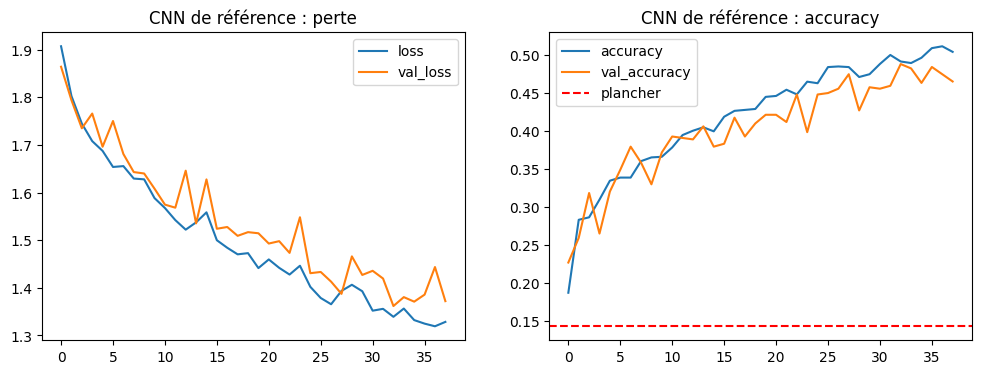

Meilleure accuracy de validation : 48.8%  (plancher : 14.3%)


In [13]:
# Courbes d'apprentissage
def tracer(historique, titre):
    h = pd.DataFrame(historique.history)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    h[["loss", "val_loss"]].plot(ax=ax1, title=f"{titre} : perte")
    h[["accuracy", "val_accuracy"]].plot(ax=ax2, title=f"{titre} : accuracy")
    ax2.axhline(1 / len(RAYONS), color="red", linestyle="--", label="plancher")
    ax2.legend()
    plt.show()

tracer(historique_cnn, "CNN de référence")
print(f"Meilleure accuracy de validation : {max(historique_cnn.history['val_accuracy']):.1%}  (plancher : {1/len(RAYONS):.1%})")

## 3. Transfert d'apprentissage

### 3.1 Choix du réseau et de la taille d'image

**Choix.** Nous retenons EfficientNetB0, pré-entraîné sur ImageNet, en entrée 224 × 224 (sa taille d'origine, celle de notre pipeline). Il est léger (5 M de paramètres), donc rapide à entraîner et à appeler depuis l'API, et il intègre son prétraitement : on lui donne directement les pixels de 0 à 255.

### 3.2 Augmentation de données

**Augmentations retenues**, tirées des observations de la 1.5 : rotation de ±15° (photos de travers), zoom de ±20 % et décalage de 10 % (échelle et cadrage très variables), luminosité et contraste de ±20 % (éclairages de cuisine, de magasin, flash).

**Écartées :** le flip horizontal (il inverse le texte des étiquettes, qui est un indice fort) et les changements de teinte (la couleur distingue des rayons : rouge du Coca, vert des Activia).

Les couches d'augmentation font partie du modèle et ne sont actives qu'à l'entraînement : la validation et le test ne sont jamais augmentés.

In [14]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.04, fill_mode="constant"),            # ±15° (0,04 tour) : photos de travers
    layers.RandomZoom((-0.2, 0.2), fill_mode="constant"),         # ±20 % : produits pris de près ou de loin
    layers.RandomTranslation(0.1, 0.1, fill_mode="constant"),     # décalage de 10 % : produit pas centré
    layers.RandomBrightness(0.2),                                 # plus clair / plus sombre : éclairages variés
    layers.RandomContrast(0.2),
], name="augmentation")

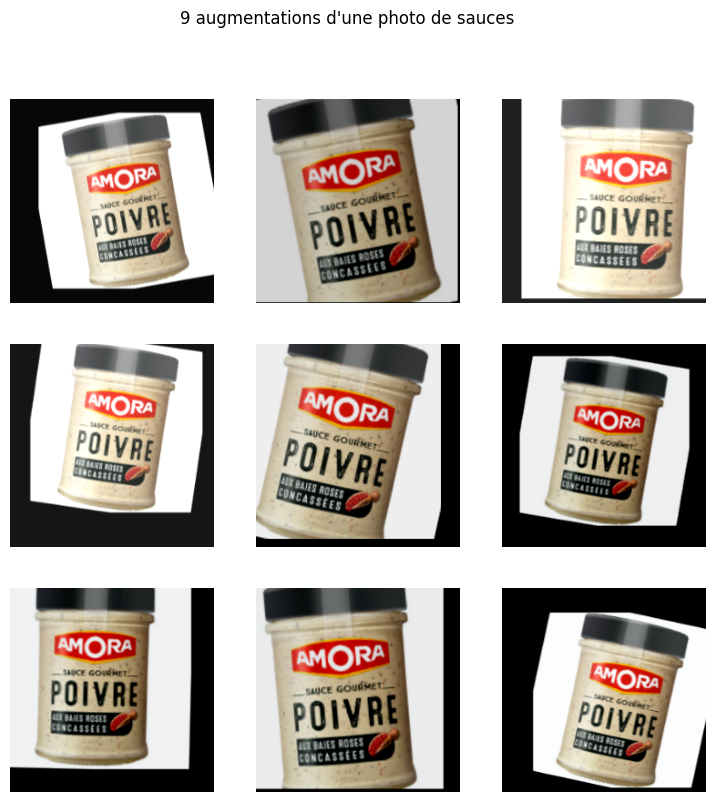

In [15]:
X, y = next(iter(train_ds))                         # un batch d'entraînement
photo = tf.cast(X[:1], "float32")                   # la première photo
plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmentation(photo, training=True)[0].numpy().astype("uint8"))  # une version augmentée différente
    plt.axis("off")
plt.suptitle(f"9 augmentations d'une photo de {RAYONS[y[0]]}")
plt.show()

### 3.3 Entraînement avec la base gelée

Les poids d'EfficientNet ne bougent pas : seule la nouvelle tête (7 rayons) est entraînée.

Epoch 1/20


E0000 00:00:1793806865.451587   77810 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_transfert_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


77/77 - 20s - 264ms/step - accuracy: 0.4453 - loss: 1.4472 - val_accuracy: 0.6248 - val_loss: 1.0193
Epoch 2/20
77/77 - 6s - 77ms/step - accuracy: 0.6302 - loss: 1.0271 - val_accuracy: 0.6590 - val_loss: 0.9080
Epoch 3/20
77/77 - 7s - 92ms/step - accuracy: 0.6571 - loss: 0.9165 - val_accuracy: 0.6971 - val_loss: 0.8391
Epoch 4/20
77/77 - 7s - 94ms/step - accuracy: 0.6939 - loss: 0.8304 - val_accuracy: 0.7124 - val_loss: 0.8108
Epoch 5/20
77/77 - 7s - 95ms/step - accuracy: 0.7233 - loss: 0.7782 - val_accuracy: 0.7105 - val_loss: 0.7944
Epoch 6/20
77/77 - 6s - 77ms/step - accuracy: 0.7204 - loss: 0.7576 - val_accuracy: 0.7333 - val_loss: 0.7767
Epoch 7/20
77/77 - 7s - 96ms/step - accuracy: 0.7388 - loss: 0.7233 - val_accuracy: 0.7238 - val_loss: 0.7604
Epoch 8/20
77/77 - 7s - 96ms/step - accuracy: 0.7482 - loss: 0.6972 - val_accuracy: 0.7181 - val_loss: 0.7541
Epoch 9/20
77/77 - 7s - 96ms/step - accuracy: 0.7596 - loss: 0.6845 - val_accuracy: 0.7429 - val_loss: 0.7387
Epoch 10/20
77/77 -

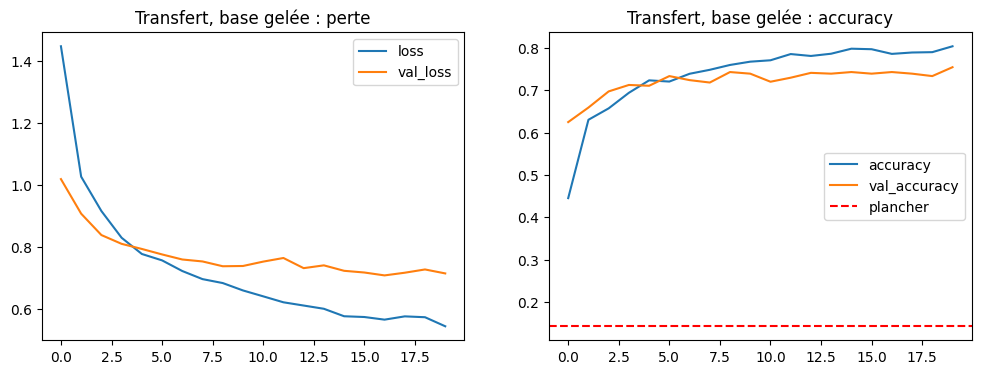

Validation : 74.3%


In [16]:
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(TAILLE, TAILLE, 3))
base.trainable = False                               # base gelée : ses poids ne bougent pas

entree = keras.Input(shape=(TAILLE, TAILLE, 3))
x = augmentation(entree)                             # 1. augmentation (active seulement à l'entraînement)
x = base(x, training=False)                          # 2. EfficientNet extrait les caractéristiques de l'image
x = layers.GlobalAveragePooling2D()(x)               # 3. résumé en un vecteur de 1 280 nombres
x = layers.Dropout(0.3)(x)
sortie = layers.Dense(len(RAYONS), activation="softmax")(x)   # 4. nouvelle tête : 7 probabilités
transfert = keras.Model(entree, sortie, name="efficientnetb0_transfert")

transfert.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
historique_gele = transfert.fit(
    train_ds, validation_data=val_ds, epochs=20, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
)
tracer(historique_gele, "Transfert, base gelée")
_, acc_gele = transfert.evaluate(val_ds, verbose=0)
print(f"Validation : {acc_gele:.1%}")
poids_geles = transfert.get_weights()     # sauvegarde du modèle gelé (repris en 3.4, 3.4 bis et 3.5)

### 3.4 Fine-tuning

On dégèle les 20 dernières couches d'EfficientNet, celles qui détectent les objets propres à ImageNet, pour les adapter aux emballages. Les premières couches (bords, couleurs, textures) restent gelées. Le taux d'apprentissage est 100 fois plus petit pour ajuster sans détruire ce qui a été appris. Les couches de BatchNormalization restent gelées pour éviter l'instabilité.

Epoch 1/50


E0000 00:00:1793809249.017158   77810 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_transfert_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


77/77 - 20s - 255ms/step - accuracy: 0.8000 - loss: 0.5601 - val_accuracy: 0.7467 - val_loss: 0.7212
Epoch 2/50
77/77 - 7s - 94ms/step - accuracy: 0.8155 - loss: 0.5360 - val_accuracy: 0.7429 - val_loss: 0.7150
Epoch 3/50
77/77 - 7s - 95ms/step - accuracy: 0.8069 - loss: 0.5247 - val_accuracy: 0.7467 - val_loss: 0.7148
Epoch 4/50
77/77 - 7s - 91ms/step - accuracy: 0.8159 - loss: 0.5142 - val_accuracy: 0.7467 - val_loss: 0.7198
Epoch 5/50
77/77 - 6s - 75ms/step - accuracy: 0.8106 - loss: 0.5167 - val_accuracy: 0.7524 - val_loss: 0.7173
Epoch 6/50
77/77 - 7s - 92ms/step - accuracy: 0.8155 - loss: 0.5121 - val_accuracy: 0.7543 - val_loss: 0.7163
Epoch 7/50
77/77 - 7s - 94ms/step - accuracy: 0.8184 - loss: 0.4960 - val_accuracy: 0.7543 - val_loss: 0.7120
Epoch 8/50
77/77 - 7s - 96ms/step - accuracy: 0.8184 - loss: 0.5114 - val_accuracy: 0.7562 - val_loss: 0.7115
Epoch 9/50
77/77 - 6s - 77ms/step - accuracy: 0.8233 - loss: 0.4902 - val_accuracy: 0.7524 - val_loss: 0.7118
Epoch 10/50
77/77 -

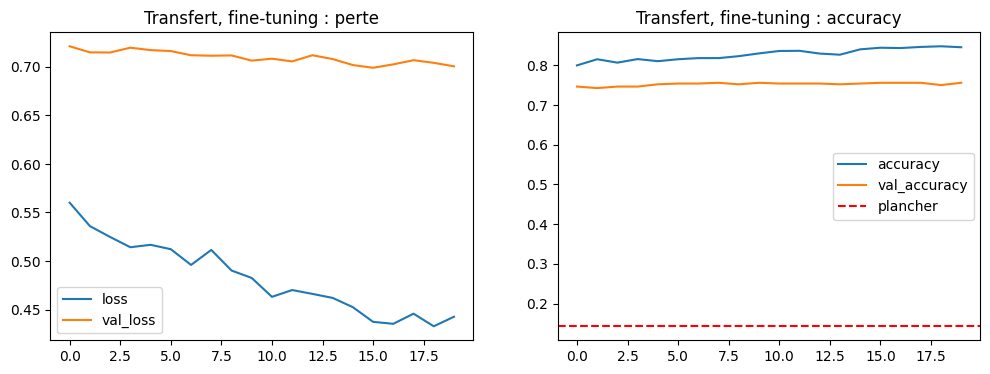

Validation : 75.6%  (base gelée : 74.3%)


In [30]:
transfert.set_weights(poids_geles)    # on repart toujours du modèle gelé, même si on relance cette cellule

base.trainable = True
for couche in base.layers[:-20]:                      # tout sauf les 20 dernières couches reste gelé
    couche.trainable = False
for couche in base.layers:                            # les BatchNormalization restent gelées (sinon instabilité)
    if isinstance(couche, layers.BatchNormalization):
        couche.trainable = False

transfert.compile(optimizer=keras.optimizers.Adam(1e-5),   # taux 100 fois plus petit : on ajuste sans casser
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
historique_ft = transfert.fit(
    train_ds, validation_data=val_ds, epochs=50, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
)
tracer(historique_ft, "Transfert, fine-tuning")
_, acc_ft = transfert.evaluate(val_ds, verbose=0)
print(f"Validation : {acc_ft:.1%}  (base gelée : {acc_gele:.1%})")

### 3.4 bis Les deux modèles sont-ils vraiment différents ? (test de McNemar)

Un écart de 2,5 points sur 525 photos ne représente qu'environ 13 photos. Pour savoir si ce n'est pas du hasard, on compare les deux modèles **photo par photo, sur la même validation** :
- les photos où les deux ont raison, ou les deux ont tort, ne disent rien sur la différence entre eux ;
- seules comptent les photos où **ils ne sont pas d'accord** : `b` = seul le modèle gelé a raison, `c` = seul le fine-tuné a raison.

Si les deux modèles se valent, ces désaccords devraient se répartir à peu près à 50/50 entre `b` et `c`, comme des pile ou face. Le test de McNemar calcule la probabilité d'obtenir un déséquilibre au moins aussi grand par pur hasard (la p-value). En dessous de 0,05, on considère l'écart comme réel.

In [18]:
from scipy.stats import binomtest

y_val = val_df["rayon"].map(NUM).values          # vrais rayons, dans l'ordre de val_ds (qui n'est pas mélangé)

# prédictions des deux versions du même modèle : on recharge temporairement les poids gelés, puis on remet les fine-tunés
poids_ft = transfert.get_weights()
pred_ft = transfert.predict(val_ds, verbose=0).argmax(axis=1)
transfert.set_weights(poids_geles)
pred_gele = transfert.predict(val_ds, verbose=0).argmax(axis=1)
transfert.set_weights(poids_ft)

juste_gele = pred_gele == y_val
juste_ft = pred_ft == y_val
print(f"Gelé : {juste_gele.sum()} / {len(y_val)} justes   |   Fine-tuné : {juste_ft.sum()} / {len(y_val)} justes")

# tableau 2 x 2 : qui a raison, qui a tort
display(pd.crosstab(pd.Series(juste_gele, name="gelé juste"), pd.Series(juste_ft, name="fine-tuné juste")))

b = int((juste_gele & ~juste_ft).sum())     # seul le gelé a raison
c = int((~juste_gele & juste_ft).sum())     # seul le fine-tuné a raison
test = binomtest(c, b + c, p=0.5)           # McNemar exact : les désaccords se répartissent-ils à 50/50 ?
print(f"Désaccords : seul le gelé a raison = {b}, seul le fine-tuné a raison = {c}")
print(f"p-value de McNemar : {test.pvalue:.3f}")

Gelé : 390 / 525 justes   |   Fine-tuné : 401 / 525 justes


fine-tuné juste,False,True
gelé juste,,
False,117,18
True,7,383


Désaccords : seul le gelé a raison = 7, seul le fine-tuné a raison = 18
p-value de McNemar : 0.043


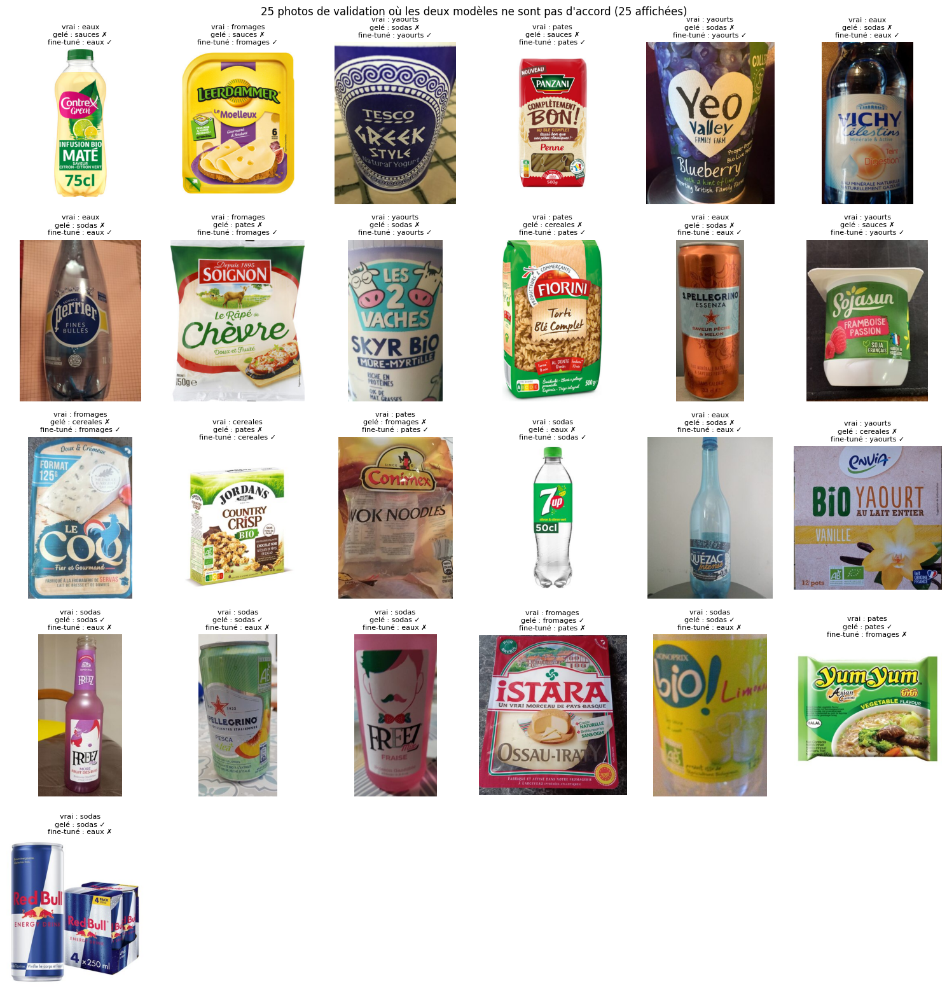

In [19]:
# planche des photos de validation sur lesquelles les deux modèles ne sont pas d'accord
val_ordre = val_df.reset_index(drop=True)
desaccord = np.where(juste_gele != juste_ft)[0]
desaccord = desaccord[np.argsort(juste_gele[desaccord])]     # d'abord celles où seul le fine-tuné a raison

n = min(len(desaccord), 36)
colonnes = 6
lignes = int(np.ceil(n / colonnes))
fig, axes = plt.subplots(lignes, colonnes, figsize=(15, 3.2 * lignes))
for case in axes.flat:
    case.axis("off")
for case, i in zip(axes.flat, desaccord[:n]):
    case.imshow(Image.open(val_ordre.loc[i, "chemin"]))
    case.set_title(
        f"vrai : {RAYONS[y_val[i]]}\n"
        f"gelé : {RAYONS[pred_gele[i]]} {'✓' if juste_gele[i] else '✗'}\n"
        f"fine-tuné : {RAYONS[pred_ft[i]]} {'✓' if juste_ft[i] else '✗'}",
        fontsize=8,
    )
fig.suptitle(f"{len(desaccord)} photos de validation où les deux modèles ne sont pas d'accord ({n} affichées)")
plt.tight_layout()
plt.show()

**Lecture** (à compléter après exécution) : valeurs de `b` et `c`, p-value, conclusion (écart réel ou bruit). Sur la planche : quels rayons le fine-tuning a-t-il appris à mieux reconnaître ? Ces photos ont-elles un point commun ?

### 3.5 Comparaison sur la même validation et choix du modèle

Les quatre scores sont mesurés sur la même validation (525 photos). Le modèle est choisi ici, **avant** d'ouvrir le test.

In [20]:
_, acc_cnn = cnn.evaluate(val_ds, verbose=0)

comparaison = pd.DataFrame({
    "modèle": ["plancher", "CNN de référence", "transfert, base gelée", "transfert + fine-tuning"],
    "accuracy validation": [1 / len(RAYONS), acc_cnn, acc_gele, acc_ft],
})
display(comparaison.style.format({"accuracy validation": "{:.1%}"}))

if acc_ft < acc_gele:                       # le fine-tuning n'a pas aidé : on revient aux poids gelés
    transfert.set_weights(poids_geles)
    print("Modèle retenu : base gelée")
else:
    print("Modèle retenu : fine-tuning")
modele = transfert                           # le modèle choisi, SUR LA VALIDATION, avant d'ouvrir le test

,modèle,accuracy validation
0,plancher,14.3%
1,CNN de référence,48.8%
2,"transfert, base gelée",74.3%
3,transfert + fine-tuning,76.4%


Modèle retenu : fine-tuning


**Lecture** (à compléter après exécution) : gain du transfert sur la référence, apport ou non du fine-tuning, modèle retenu.

## 4. Seuil de confiance (sur la validation)

La brique répond « je ne sais pas » quand la confiance du modèle (sa plus haute probabilité) est sous un seuil. Pour NutriScope, **un rayon faux annoncé avec assurance est plus gênant qu'un « je ne sais pas »** : l'utilisateur peut alors reprendre la photo ou choisir le rayon lui-même.

**Objectif :** quand la brique annonce un rayon, elle doit avoir raison au moins 90 % du temps. Le seuil retenu est le plus petit qui atteint cet objectif sur la validation, pour garder la plus grande couverture possible. Il est fixé ici, avant d'ouvrir le test.

,seuil,photos acceptées,couverture,accuracy si réponse
0,0.300000,524,99.8%,76.5%
1,0.350000,521,99.2%,76.6%
2,0.400000,515,98.1%,77.1%
3,0.450000,503,95.8%,78.1%
4,0.500000,491,93.5%,78.4%
5,0.550000,459,87.4%,81.0%
6,0.600000,441,84.0%,82.8%
7,0.650000,415,79.0%,84.8%
8,0.700000,393,74.9%,86.5%
9,0.750000,369,70.3%,88.1%


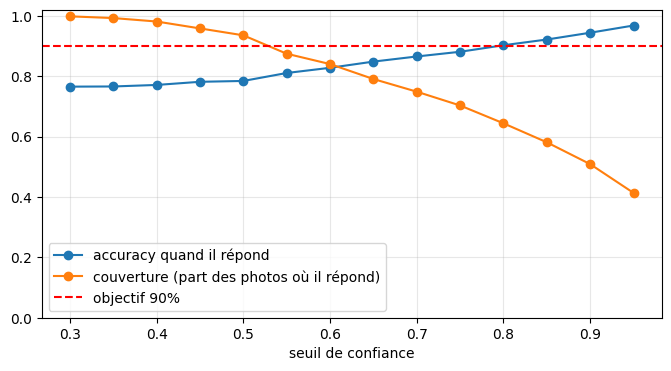

In [27]:
OBJECTIF = 0.90      # accuracy minimale exigée quand la brique annonce un rayon

proba_val = modele.predict(val_ds, verbose=0)       # 525 x 7 probabilités
confiance = proba_val.max(axis=1)                   # la plus haute probabilité de chaque photo
juste = proba_val.argmax(axis=1) == y_val           # le rayon prédit est-il le bon ?

seuils = np.round(np.arange(0.30, 0.96, 0.05), 2)
courbe = pd.DataFrame({
    "seuil": seuils,
    "photos acceptées": [(confiance >= s).sum() for s in seuils],
    "couverture": [(confiance >= s).mean() for s in seuils],
    "accuracy si réponse": [juste[confiance >= s].mean() for s in seuils],
})
display(courbe.style.format({"couverture": "{:.1%}", "accuracy si réponse": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(courbe["seuil"], courbe["accuracy si réponse"], marker="o", label="accuracy quand il répond")
ax.plot(courbe["seuil"], courbe["couverture"], marker="o", label="couverture (part des photos où il répond)")
ax.axhline(OBJECTIF, color="red", linestyle="--", label=f"objectif {OBJECTIF:.0%}")
ax.set_xlabel("seuil de confiance")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [28]:
atteint = courbe[courbe["accuracy si réponse"] >= OBJECTIF]
SEUIL = float(atteint["seuil"].min())                # le plus petit seuil qui atteint l'objectif
ligne = courbe[courbe["seuil"] == SEUIL].iloc[0]
print(f"Seuil retenu : {SEUIL:.2f} -> répond sur {ligne['couverture']:.1%} des photos, "
      f"avec {ligne['accuracy si réponse']:.1%} de bonnes réponses")

ligne60 = courbe[courbe["seuil"] == 0.60].iloc[0]
print(f"Pour comparaison, seuil 0.60 -> couverture {ligne60['couverture']:.1%}, "
      f"accuracy {ligne60['accuracy si réponse']:.1%}")

Seuil retenu : 0.80 -> répond sur 64.4% des photos, avec 90.2% de bonnes réponses
Pour comparaison, seuil 0.60 -> couverture 84.0%, accuracy 82.8%


**Lecture** (à compléter après exécution) : seuil retenu, couverture et accuracy correspondantes, ce que ça veut dire pour l'utilisateur (sur 10 photos, combien de réponses, combien de « je ne sais pas »). Limite : aux seuils élevés, peu de photos restent, donc l'accuracy y est moins fiable.

## 5. Évaluation sur le test (une seule fois)

### 5.1 Scores

In [22]:
# À compléter : accuracy globale (avec et sans seuil), accuracy par rayon, rapport de classification

### 5.2 Matrice de confusion

In [23]:
# À compléter

**Confusions principales** (à compléter) :

### 5.3 Planche des erreurs les plus parlantes

In [24]:
# À compléter : erreurs les plus confiantes et variées, avec vrai rayon, rayon prédit et confiance

**Commentaires** (à compléter, erreur par erreur) : donnée ambiguë, erreur d'étiquette ou limite du modèle ?

Pistes d'amélioration qui en découlent (reprises dans `docs/ml/limites_images.md`) :

## 6. Sauvegarde du modèle et de ses métadonnées

In [25]:
# À compléter : models/<nom>.keras + JSON (rayons dans l'ordre des sorties, taille d'image, seuil, score de test)

## 7. Vérification de la brique hors du notebook

In [26]:
# À compléter : importer src/classifieur_images.py et prédire quelques photos du test